# MSD and g(r) Analysis for MATILDA.FT Binary Output

Computes:
- **Mean Square Displacement (MSD)** per particle type with PBC-unwrapped trajectories
- **Radial Distribution Function g(r)** for nanoparticles (last particle type, `ntypes-1`)

Reads `positions.bin` files produced by `write_binary()` in `src/io_utils.cu`.

## Binary Format Reference (`src/io_utils.cu`)
**Header (once):** `ns` (int32), `Dim` (int32), `L[3]` (float32×3), `tp[ns]` (int32×ns), `molecID[ns]` (int32×ns)  
**Per frame:** `positions[ns*Dim]` (float32), stored particle-major: `pos[i*Dim + j]` = coord `j` of particle `i`

In [22]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from glob import glob
from tqdm import tqdm

## Configuration
Set these parameters before running the analysis.

In [78]:
# --- Directory and file settings ---
# Points to the Results folder produced by move_results; pos files must be copied there too
sim_base_dir = "/home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions"
file_pattern = "**/*_pos.bin"

# --- Timing ---
delt         = 0.005   # simulation timestep size (simulation time units)
frames_apart = 50000   # simulation timesteps between saved frames
dt_per_frame = delt * frames_apart   # = 50.0 simulation time units per frame

# --- Equilibration ---
skip_frames  = 0

# --- g(r) settings ---
n_gr_bins    = 100
gr_rmax      = None   # None -> auto-set to L_min / 2

# --- Filters (set to None to include all) ---
fracs_of_interest  = [0.5]          # NP fractions
pots_of_interest   = [10.0, 17.5]   # potential values
nb_of_interest     = [5, 20]        # polymer lengths (Nb)
radii_of_interest  = [5]   # NP radii

# --- Filename regex for files produced by move_results ---
# Matches: equil_PS_in_NP_frac_{frac}_rad_{rad}_POT_{pot}_Nb_{nb}_rep_{rep}_pos.bin
filename_re = re.compile(
    r"NP_frac_([\d.]+)_rad_([\d.]+)_POT_([\d.]+)_Nb_(\d+)_rep_(\d+)"
)

# NP type is automatically ntypes-1 per file.

## Binary Reader
Follows the exact format written by `init_binary_output()` + `write_binary()` in `src/io_utils.cu`.

In [79]:
def read_positions_bin(filepath, verbose=False):
    """
    Read a MATILDA.FT positions.bin file.

    Binary layout (io_utils.cu::init_binary_output + write_binary):
      Header: ns(i32), Dim(i32), L[3](f32x3), tp[ns](i32xns), molecID[ns](i32xns)
      Frames: positions[ns*Dim](f32) repeated, particle-major order

    Returns
    -------
    ns     : int
    Dim    : int
    L      : float array [Dim]  (box lengths)
    tp     : int array [ns]     (particle types, 0-indexed)
    molID  : int array [ns]     (molecule IDs, 0-indexed)
    frames : float array [nframes, ns, Dim]
    """
    with open(filepath, 'rb') as f:
        ns    = np.frombuffer(f.read(4),      dtype=np.int32)[0]
        Dim   = np.frombuffer(f.read(4),      dtype=np.int32)[0]
        L_all = np.frombuffer(f.read(12),     dtype=np.float32)  # always 3 floats written
        tp    = np.frombuffer(f.read(4*ns),   dtype=np.int32).copy()
        molID = np.frombuffer(f.read(4*ns),   dtype=np.int32).copy()

        frame_bytes = 4 * ns * Dim
        raw_frames  = []
        while True:
            raw = f.read(frame_bytes)
            if len(raw) < frame_bytes:
                break
            raw_frames.append(
                np.frombuffer(raw, dtype=np.float32).reshape(ns, Dim)
            )

    frames = np.array(raw_frames)  # shape: (nframes, ns, Dim)
    L      = L_all[:Dim]

    if verbose:
        ntypes = len(np.unique(tp))
        print(f"  ns={ns}, Dim={Dim}, L={L}, ntypes={ntypes}, nframes={len(frames)}")

    return ns, Dim, L, tp, molID, frames

## MSD Computation (PBC-unwrapped, multiple time origins)

In [80]:
def unwrap_trajectory(frames, L):
    """
    Unwrap particle positions across periodic boundaries.

    Parameters
    ----------
    frames : (nframes, ns, Dim)
    L      : box lengths [Dim]

    Returns
    -------
    unwrapped : (nframes, ns, Dim)
    """
    nframes, ns, Dim = frames.shape
    unwrapped = frames.copy().astype(np.float64)
    for t in range(1, nframes):
        delta = unwrapped[t] - unwrapped[t-1]
        for d in range(Dim):
            delta[:, d] -= L[d] * np.round(delta[:, d] / L[d])
        unwrapped[t] = unwrapped[t-1] + delta
    return unwrapped


def compute_msd(frames, L, tp, skip=0):
    """
    Compute MSD per particle type with multiple time origins.

    Parameters
    ----------
    frames : (nframes, ns, Dim)
    L      : box lengths [Dim]
    tp     : particle type array [ns]
    skip   : number of leading frames to discard

    Returns
    -------
    msd_by_type : dict  type_id -> msd array [max_lag]
    """
    frames   = frames[skip:]
    nframes  = frames.shape[0]
    ntypes   = len(np.unique(tp))
    max_lag  = nframes // 2

    unwrapped = unwrap_trajectory(frames, L)

    msd_by_type = {}
    for t_id in range(ntypes):
        mask = (tp == t_id)
        pos  = unwrapped[:, mask, :]   # (nframes, N_type, Dim)

        msd = np.zeros(max_lag)
        for lag in range(1, max_lag):
            disp      = pos[lag:] - pos[:nframes-lag]
            msd[lag]  = np.mean(np.sum(disp**2, axis=-1))

        msd_by_type[t_id] = msd[1:]   # drop lag=0
    return msd_by_type

## g(r) Computation (NP–NP, time-averaged)

In [81]:
def compute_gr(frames, L, tp, np_type_id, n_bins, r_max=None, skip=0):
    """
    Compute time-averaged g(r) for nanoparticle type np_type_id.

    Parameters
    ----------
    frames      : (nframes, ns, Dim)
    L           : box lengths [Dim]
    tp          : particle type array [ns]
    np_type_id  : particle type index for nanoparticles
    n_bins      : number of radial bins
    r_max       : max r; None -> L_min / 2
    skip        : leading frames to discard

    Returns
    -------
    r_mid : bin centers [n_bins]
    gr    : g(r) values  [n_bins]
    """
    frames = frames[skip:]
    Dim    = frames.shape[2]

    if r_max is None:
        r_max = float(np.min(L)) / 2.0

    r_edges = np.linspace(0.0, r_max, n_bins + 1)
    r_mid   = 0.5 * (r_edges[1:] + r_edges[:-1])
    counts  = np.zeros(n_bins, dtype=np.float64)

    mask = (tp == np_type_id)
    n_NP = int(np.sum(mask))
    V    = float(np.prod(L))

    if n_NP < 2:
        print(f"  Warning: only {n_NP} NP particles found for type {np_type_id}")
        return r_mid, np.zeros(n_bins)

    for frame in frames:
        np_pos = frame[mask].astype(np.float64)   # (n_NP, Dim)
        for i in range(n_NP - 1):
            dr = np_pos[i+1:] - np_pos[i]          # (n_NP-i-1, Dim)
            for d in range(Dim):
                dr[:, d] -= L[d] * np.round(dr[:, d] / L[d])
            r = np.linalg.norm(dr, axis=1)
            hist, _ = np.histogram(r, bins=r_edges)
            counts  += 2.0 * hist  # symmetric pair

    nframes_used = len(frames)
    if Dim == 3:
        shell_vols = (4.0/3.0) * np.pi * (r_edges[1:]**3 - r_edges[:-1]**3)
    else:  # 2D
        shell_vols = np.pi * (r_edges[1:]**2 - r_edges[:-1]**2)

    rho_ideal = n_NP / V
    gr = counts / (nframes_used * n_NP * rho_ideal * shell_vols)
    return r_mid, gr

## Discover Files and Run Analysis

In [82]:
files = sorted(glob(os.path.join(sim_base_dir, file_pattern), recursive=True))
print(f"Found {len(files)} positions.bin files:")
for f in files:
    print(f"  {f}")

Found 4 positions.bin files:
  /home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_10.0_Nb_20_rep_0_pos.bin
  /home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_10.0_Nb_5_rep_0_pos.bin
  /home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_17.5_Nb_20_rep_0_pos.bin
  /home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_17.5_Nb_5_rep_0_pos.bin


In [83]:
def _in(val, lst, tol=1e-4):
    """Float-safe membership test."""
    return any(abs(val - v) < tol for v in lst)

# Storage for results
msd_results = []
gr_results  = []

for filepath in tqdm(files, desc="Processing files"):
    filename = os.path.basename(filepath)

    # --- Parse all parameters from filename ---
    m = filename_re.search(filename)
    if not m:
        print(f"  Warning: could not parse '{filename}', skipping.")
        continue

    np_frac = float(m.group(1))
    rad_val = float(m.group(2))
    pot_val = float(m.group(3))
    nb_val  = int(m.group(4))
    rep_val = int(m.group(5))

    # --- Apply filters ---
    if not _in(np_frac, fracs_of_interest): continue
    if not _in(rad_val, radii_of_interest): continue
    if not _in(pot_val, pots_of_interest):  continue
    if not _in(nb_val,  nb_of_interest):    continue

    param_label = f"frac={np_frac}, rad={rad_val}, POT={pot_val}, Nb={nb_val}"
    print(f"\n{filepath}  [{param_label}]")

    # --- Read binary file ---
    ns, Dim, L, tp, molID, frames = read_positions_bin(filepath, verbose=True)

    ntypes     = len(np.unique(tp))
    np_type_id = ntypes - 1
    nframes    = frames.shape[0]

    if nframes <= skip_frames + 2:
        print(f"  Skipping: too few frames ({nframes})")
        continue

    lag_times = np.arange(1, nframes // 2) * dt_per_frame

    # --- MSD ---
    msd_by_type = compute_msd(frames, L, tp, skip=skip_frames)
    for t_id, msd in msd_by_type.items():
        msd_results.append({
            "param":     param_label,
            "frac":      np_frac,
            "rad":       rad_val,
            "pot":       pot_val,
            "nb":        nb_val,
            "rep":       rep_val,
            "filepath":  filepath,
            "type_id":   t_id,
            "lag_times": lag_times[:len(msd)],
            "msd":       msd,
        })

    # --- g(r) ---
    r_mid, gr = compute_gr(
        frames, L, tp, np_type_id,
        n_bins=n_gr_bins, r_max=gr_rmax, skip=skip_frames
    )
    gr_results.append({
        "param":    param_label,
        "frac":     np_frac,
        "rad":      rad_val,
        "pot":      pot_val,
        "nb":       nb_val,
        "rep":      rep_val,
        "filepath": filepath,
        "np_type":  np_type_id,
        "r":        r_mid,
        "gr":       gr,
    })

# Sort by (frac, pot, nb, rad) for consistent ordering
msd_results.sort(key=lambda x: (x["frac"], x["pot"], x["nb"], x["rad"]))
gr_results.sort(key=lambda x: (x["frac"], x["pot"], x["nb"], x["rad"]))

print("\nDone.")

Processing files:   0%|          | 0/4 [00:00<?, ?it/s]


/home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_10.0_Nb_20_rep_0_pos.bin  [frac=0.5, rad=5.0, POT=10.0, Nb=20]
  ns=72458, Dim=3, L=[52.5 52.5 52.5], ntypes=3, nframes=21


Processing files:  25%|██▌       | 1/4 [00:01<00:03,  1.26s/it]


/home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_10.0_Nb_5_rep_0_pos.bin  [frac=0.5, rad=5.0, POT=10.0, Nb=5]
  ns=72488, Dim=3, L=[52.5 52.5 52.5], ntypes=3, nframes=21


Processing files:  50%|█████     | 2/4 [00:02<00:02,  1.00s/it]


/home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_17.5_Nb_20_rep_0_pos.bin  [frac=0.5, rad=5.0, POT=17.5, Nb=20]
  ns=72458, Dim=3, L=[52.5 52.5 52.5], ntypes=3, nframes=21


Processing files:  75%|███████▌  | 3/4 [00:02<00:00,  1.10it/s]


/home/gabriel/Tests/Confined_PS_Equilibration/Results/Positions/equil_PS_in_NP_frac_0.5_rad_5_POT_17.5_Nb_5_rep_0_pos.bin  [frac=0.5, rad=5.0, POT=17.5, Nb=5]
  ns=72488, Dim=3, L=[52.5 52.5 52.5], ntypes=3, nframes=21


Processing files: 100%|██████████| 4/4 [00:03<00:00,  1.07it/s]


Done.


## Plot: MSD vs Time (log-log, per particle type)

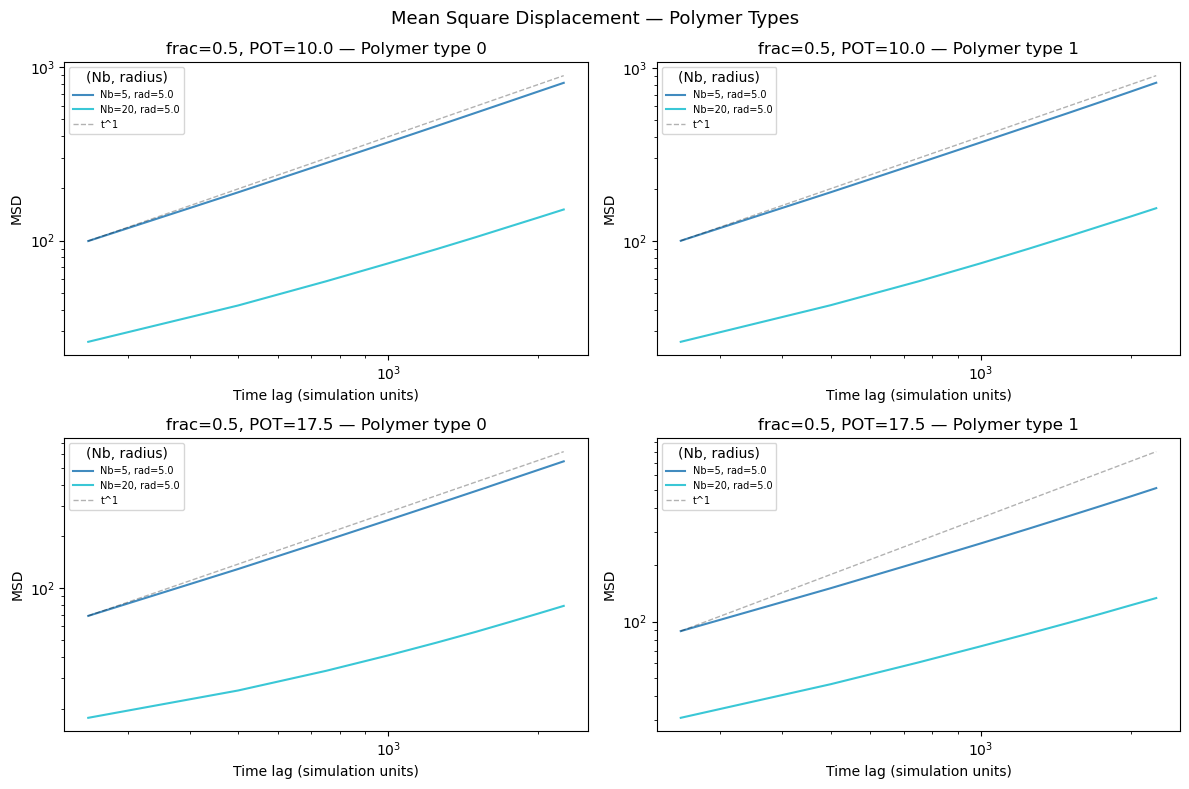

In [84]:
# Grid: rows = (frac, POT) pairs, cols = polymer type (0, 1)
# Lines within each subplot: colored by (Nb, radius) combination
polymer_types = [0, 1]
type_ids  = [t for t in polymer_types if any(r["type_id"] == t for r in msd_results)]
fp_pairs  = sorted(set((r["frac"], r["pot"]) for r in msd_results))

nb_rad_pairs = sorted(set((r["nb"], r["rad"]) for r in msd_results))
cmap         = plt.cm.tab10
pair_colors  = {p: cmap(i / max(len(nb_rad_pairs) - 1, 1))
                for i, p in enumerate(nb_rad_pairs)}

nrows = len(fp_pairs)
ncols = len(type_ids)
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)

for row_idx, (frac, pot) in enumerate(fp_pairs):
    for col_idx, t_id in enumerate(type_ids):
        ax   = axes[row_idx][col_idx]
        rows = [r for r in msd_results
                if r["type_id"] == t_id
                and _in(r["frac"], [frac]) and _in(r["pot"], [pot])]

        for row in rows:
            t     = row["lag_times"]
            msd   = row["msd"]
            valid = (t > 0) & (msd > 0)
            pair  = (row["nb"], row["rad"])
            ax.loglog(t[valid], msd[valid],
                      label=f"Nb={row['nb']}, rad={row['rad']}",
                      color=pair_colors[pair], alpha=0.85)

        # Reference slope lines
        ref_rows = [r for r in rows if np.any((r["lag_times"] > 0) & (r["msd"] > 0))]
        if ref_rows:
            r0    = ref_rows[0]
            valid = (r0["lag_times"] > 0) & (r0["msd"] > 0)
            t_v, m_v = r0["lag_times"][valid], r0["msd"][valid]
            if len(t_v):
                t0, m0 = t_v[0], m_v[0]
                t_line = np.array([t0, t_v[-1]])
                scale  = m0 / t0
                ax.loglog(t_line, scale * t_line,    'k--', lw=1, alpha=0.3, label='t^1')

        ax.set_xlabel("Time lag (simulation units)")
        ax.set_ylabel("MSD")
        ax.set_title(f"frac={frac}, POT={pot} — Polymer type {t_id}")
        ax.legend(title="(Nb, radius)", fontsize=7)

plt.suptitle("Mean Square Displacement — Polymer Types", fontsize=13)
plt.tight_layout()
plt.savefig("msd_per_type.png", dpi=150)
plt.show()

## Plot: g(r) for Nanoparticles

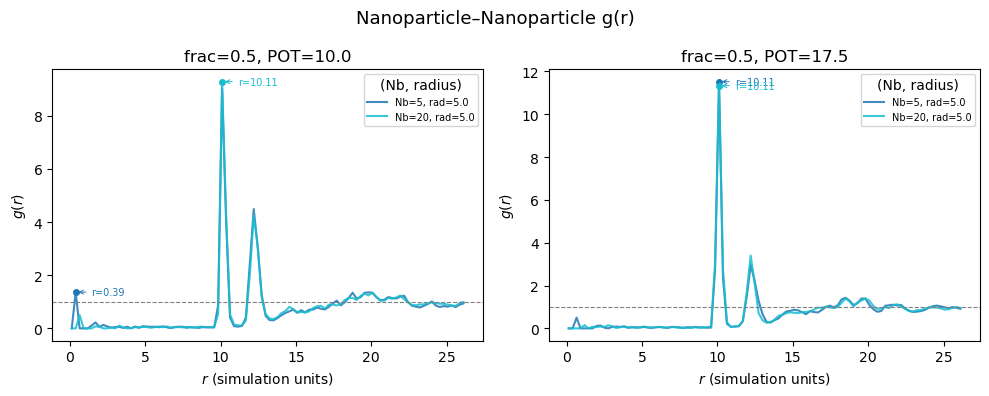

In [85]:
from scipy.signal import find_peaks

# Grid: one subplot per (frac, POT) pair
# Lines within each subplot: colored by (Nb, radius) combination
fp_pairs     = sorted(set((r["frac"], r["pot"]) for r in gr_results))
nb_rad_pairs = sorted(set((r["nb"], r["rad"])   for r in gr_results))

cmap        = plt.cm.tab10
pair_colors = {p: cmap(i / max(len(nb_rad_pairs) - 1, 1))
               for i, p in enumerate(nb_rad_pairs)}

ncols = len(fp_pairs)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 4), squeeze=False)

for col_idx, (frac, pot) in enumerate(fp_pairs):
    ax   = axes[0][col_idx]
    rows = [r for r in gr_results
            if _in(r["frac"], [frac]) and _in(r["pot"], [pot])]

    for row in rows:
        r_mid = row["r"]
        gr    = row["gr"]
        pair  = (row["nb"], row["rad"])
        color = pair_colors[pair]

        ax.plot(r_mid, gr,
                label=f"Nb={row['nb']}, rad={row['rad']}",
                color=color, alpha=0.85)

        # Annotate first peak above g(r)=1; fall back to any peak
        peaks, _ = find_peaks(gr, height=1.0, distance=3)
        if len(peaks) == 0:
            peaks, _ = find_peaks(gr, distance=3)
        if len(peaks) > 0:
            idx    = peaks[0]
            r_peak = r_mid[idx]
            g_peak = gr[idx]
            ax.plot(r_peak, g_peak, 'o', color=color, markersize=4, zorder=5)
            ax.annotate(f"r={r_peak:.2f}",
                        xy=(r_peak, g_peak),
                        xytext=(r_peak + (r_mid[-1] - r_mid[0]) * 0.04, g_peak),
                        fontsize=7, color=color, va='center',
                        arrowprops=dict(arrowstyle='->', color=color, lw=0.7))

    ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_xlabel(r"$r$ (simulation units)")
    ax.set_ylabel(r"$g(r)$")
    ax.set_title(f"frac={frac}, POT={pot}")
    ax.legend(title="(Nb, radius)", fontsize=7)

plt.suptitle("Nanoparticle–Nanoparticle g(r)", fontsize=13)
plt.tight_layout()
plt.savefig("gr_nanoparticles.png", dpi=150)
plt.show()

## Export Results to CSV (optional)

In [86]:
# --- MSD CSV ---
msd_rows = []
for row in msd_results:
    for lag, msd_val in zip(row["lag_times"], row["msd"]):
        msd_rows.append({"param": row["param"], "type_id": row["type_id"],
                         "lag_time": lag, "msd": msd_val})
pd.DataFrame(msd_rows).to_csv("msd_results.csv", index=False)
print("Saved msd_results.csv")

# --- g(r) CSV ---
gr_rows = []
for row in gr_results:
    for r_val, gr_val in zip(row["r"], row["gr"]):
        gr_rows.append({"param": row["param"], "np_type": row["np_type"],
                        "r": r_val, "gr": gr_val})
pd.DataFrame(gr_rows).to_csv("gr_results.csv", index=False)
print("Saved gr_results.csv")

Saved msd_results.csv
Saved gr_results.csv
